# Time alignment: Kalshi vs trade[XYZ]

Checks that the two collections share one clock, so they can be plotted and joined against each
other. Everything is in **UTC epoch ms** on disk; here it is converted to tz-aware UTC timestamps.

1. Coverage: what time span each source covers, on one axis
2. Kalshi 15-min settlements overlaid on trade[XYZ] 1-min prices
3. Lag test: at which minute offset do the two venues agree best? (should be 0)
4. Inside one 15-min market: Kalshi YES price vs trade[XYZ] price minus strike
5. End-of-day commodity settlements vs trade[XYZ] at the same instant
6. Daily series (temps, gas, fed, WTI) on a shared date axis

In [1]:
import os
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path(os.environ.get("PARAGON_DATA_ROOT", ""))
if not (ROOT / "kalshi.duckdb").exists():
    ROOT = Path(r"C:\Users\krish\OneDrive\Desktop\Paragon\HyperliquidData")
con = duckdb.connect()
con.execute(f"ATTACH '{(ROOT / 'kalshi.duckdb').as_posix()}' AS kx (READ_ONLY)")
con.execute(f"ATTACH '{(ROOT / 'hl.duckdb').as_posix()}' AS hl (READ_ONLY)")

def q(sql):
    return con.sql(sql).df()

def ts(ms):
    return pd.to_datetime(ms, unit="ms", utc=True)

MIN = 60_000
# Kalshi 15-min series -> trade[XYZ] symbol tracking the same underlying
PAIRS = {"KXGOLD15M": "GOLD", "KXSILVER15M": "SILVER", "KXWTI15M": "CL",
         "KXCOPPER15M": "COPPER", "KXBRENT15M": "BRENTOIL"}
plt.rcParams.update({"figure.figsize": (13, 4.5), "axes.grid": True, "grid.alpha": .3})

## 1. Coverage on one time axis

,src,t0,t1
0,KX settles: fed,2021-07-26 23:00:00+00:00,2026-10-28 17:59:00+00:00
1,KX settles: weather_high,2021-08-20 03:59:00+00:00,2026-10-31 08:00:00+00:00
2,KX settles: commodities_eod,2022-09-09 18:30:00+00:00,2026-10-30 18:30:00+00:00
3,KX settles: gas_us,2023-09-18 13:55:00+00:00,2026-10-31 03:59:00+00:00
4,KX 1m candles (all),2025-08-06 16:00:00+00:00,2026-10-31 21:16:00+00:00
5,HL 1d candles,2025-10-13 00:00:00+00:00,2026-10-31 00:00:00+00:00
6,KX settles: btc_15m,2025-12-10 22:00:00+00:00,2026-10-31 21:15:00+00:00
7,KX settles: weather_low,2025-12-14 13:21:19.063000+00:00,2026-10-31 08:00:00+00:00
8,HL 1h candles,2026-03-10 07:00:00+00:00,2026-10-31 08:00:00+00:00
9,KX settles: commodities_15m,2026-07-31 18:15:00+00:00,2026-10-31 04:00:00+00:00


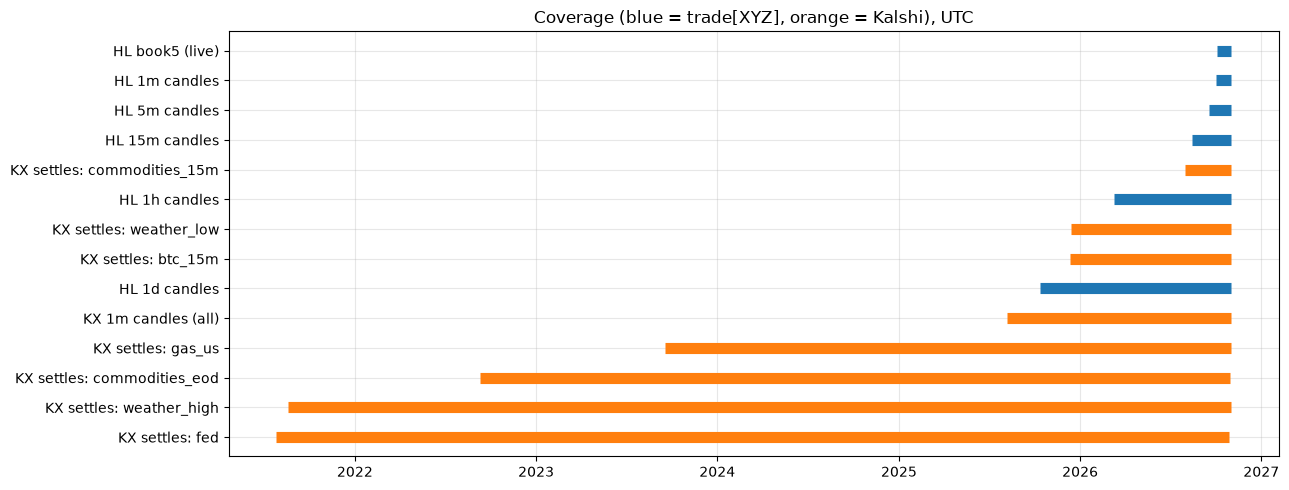

In [2]:
spans = pd.concat([
    q("""select 'HL ' || interval || ' candles' src, min(open_ms) t0, max(open_ms) t1
         from hl.candles where dex='xyz' group by interval"""),
    q("select 'HL book5 (live)' src, min(rx_ns)//1000000 t0, max(rx_ns)//1000000 t1 from hl.book5 where sym='GOLD'"),
    q("""select 'KX settles: ' || adapter src, min(close_ms) t0, max(close_ms) t1
         from kx.settlements group by adapter"""),
    q("select 'KX 1m candles (all)' src, min(end_ms) t0, max(end_ms) t1 from kx.candles"),
])
spans = spans.sort_values("t0").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 5))
for i, r in spans.iterrows():
    ax.plot([ts(r.t0), ts(r.t1)], [i, i], lw=8, solid_capstyle="butt",
            color="tab:blue" if r.src.startswith("HL") else "tab:orange")
ax.set_yticks(range(len(spans)), spans.src)
ax.set_title("Coverage (blue = trade[XYZ], orange = Kalshi), UTC")
plt.tight_layout()
spans.assign(t0=ts(spans.t0), t1=ts(spans.t1))

## 2. Kalshi 15-min settles on top of trade[XYZ] 1-min closes

Each Kalshi 15-min market settles on the 1-minute close at its `close_ms` (`expiration_value`),
and its strike is the previous window's settle. If the clocks agree, the orange dots sit on the
blue line.

level gap Kalshi - HL: median -2.65, IQR -3.39..-2.24  (a constant gap is perp basis / reference-price difference, not a timing error)


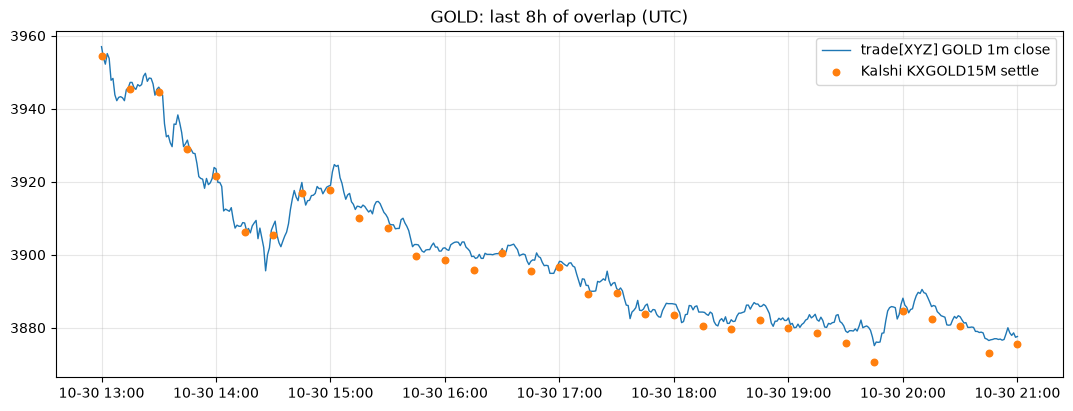

In [3]:
SER, SYM = "KXGOLD15M", "GOLD"
k = q(f"""select close_ms, floor_strike, try_cast(expiration_value as double) v, result
          from kx.settlements where series='{SER}' and v is not null""")
h = q(f"select open_ms, close from hl.candles where interval='1m' and dex='xyz' and sym='{SYM}'")
# A 1-min candle that opens at t closes at t + 1 min: index by its close time
h["end_ms"] = h.open_ms + MIN
hs = h.set_index("end_ms").close.sort_index()

day_end = k.close_ms[k.close_ms.between(hs.index.min(), hs.index.max())].max()
lo, hi = day_end - 8 * 3600_000, day_end
kk, hh = k[k.close_ms.between(lo, hi)], hs[(hs.index >= lo) & (hs.index <= hi)]
fig, ax = plt.subplots()
ax.plot(ts(hh.index), hh.values, lw=1, label=f"trade[XYZ] {SYM} 1m close")
ax.scatter(ts(kk.close_ms), kk.v, s=22, color="tab:orange", zorder=3, label=f"Kalshi {SER} settle")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M", tz="UTC"))
ax.set_title(f"{SYM}: last 8h of overlap (UTC)"); ax.legend()
basis = (kk.set_index("close_ms").v - hs.reindex(kk.close_ms).values).dropna()
print(f"level gap Kalshi - HL: median {basis.median():+.2f}, IQR {basis.quantile(.25):+.2f}..{basis.quantile(.75):+.2f}"
      "  (a constant gap is perp basis / reference-price difference, not a timing error)")

## 3. Lag test

Correlate the Kalshi 15-min move (`settle - strike`) with the trade[XYZ] move over the same
window shifted by `off` minutes. Correlation should peak sharply at **0**: a peak at +1 would mean
Kalshi's timestamps run a minute behind ours, and so on. Moves are used rather than levels so any
constant basis between the two references drops out.

,kalshi,hl,n_windows,best_offset_min,corr
0,KXGOLD15M,GOLD,1262,0,0.9825
1,KXSILVER15M,SILVER,685,0,0.9965
2,KXWTI15M,CL,1432,0,0.9949
3,KXCOPPER15M,COPPER,684,0,0.9018
4,KXBRENT15M,BRENTOIL,622,0,0.9842


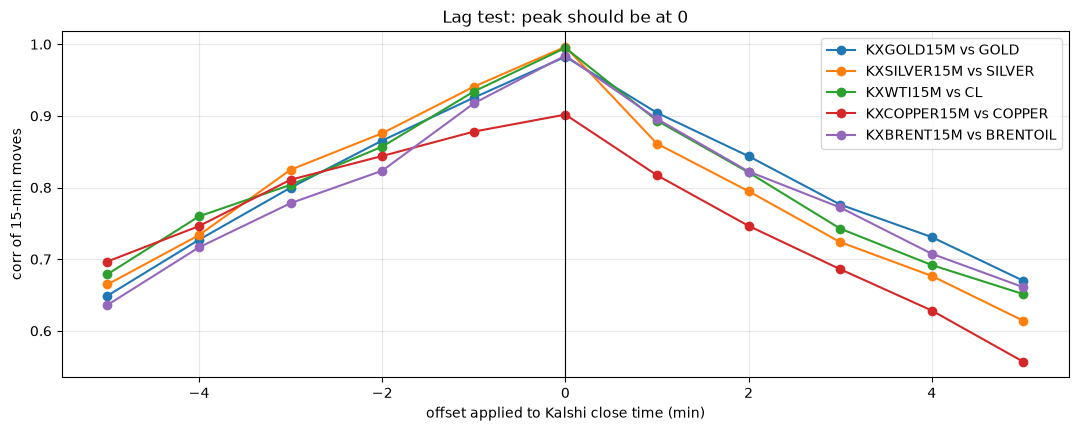

In [4]:
def lag_curve(ser, sym, offsets=range(-5, 6)):
    k = q(f"""select close_ms, floor_strike s0, try_cast(expiration_value as double) v
              from kx.settlements where series='{ser}' and v is not null and floor_strike is not null""")
    h = q(f"select open_ms + {MIN} end_ms, close from hl.candles where interval='1m' and dex='xyz' and sym='{sym}'")
    if k.empty or h.empty:
        return None
    hs = h.set_index("end_ms").close
    dk = (k.v - k.s0).values
    out = []
    for off in offsets:
        t1 = hs.reindex(k.close_ms + off * MIN).values
        t0 = hs.reindex(k.close_ms - 15 * MIN + off * MIN).values
        m = ~np.isnan(t1 - t0)
        out.append((off, m.sum(), np.corrcoef(dk[m], (t1 - t0)[m])[0, 1] if m.sum() > 20 else np.nan))
    return pd.DataFrame(out, columns=["offset_min", "n", "corr"])

fig, ax = plt.subplots()
summary = []
for ser, sym in PAIRS.items():
    c = lag_curve(ser, sym)
    if c is None or c["corr"].isna().all():
        continue
    ax.plot(c.offset_min, c["corr"], marker="o", label=f"{ser} vs {sym}")
    best = c.loc[c["corr"].idxmax()]
    summary.append((ser, sym, int(best.n), int(best.offset_min), round(best["corr"], 4)))
ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("offset applied to Kalshi close time (min)"); ax.set_ylabel("corr of 15-min moves")
ax.set_title("Lag test: peak should be at 0"); ax.legend()
pd.DataFrame(summary, columns=["kalshi", "hl", "n_windows", "best_offset_min", "corr"])

## 4. Inside one 15-min market

Kalshi's YES price (1-min candles, probability that the settle ends >= strike) against trade[XYZ]
price minus that strike. When the price crosses the strike the probability should cross 0.5 at
the same minute.

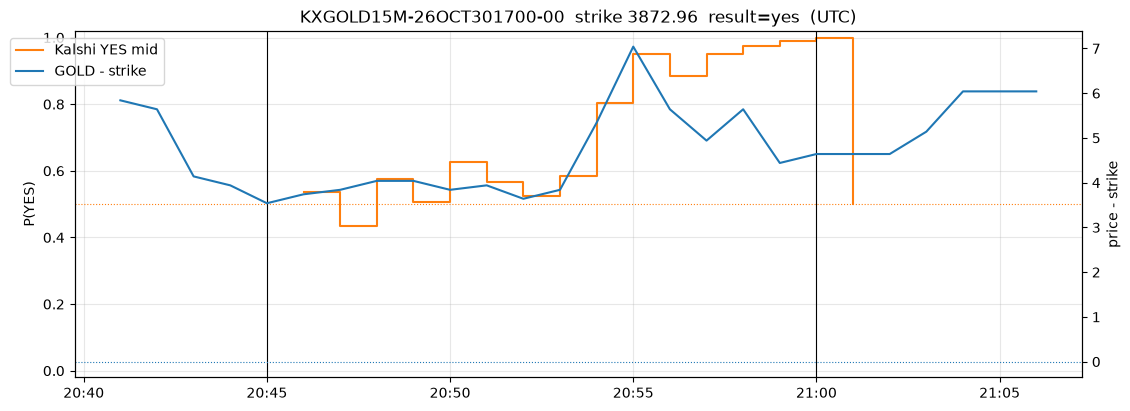

In [5]:
SER, SYM = "KXGOLD15M", "GOLD"
m = q(f"""select s.ticker, s.open_ms, s.close_ms, s.floor_strike, s.result, s.volume
          from kx.settlements s where series='{SER}' and floor_strike is not null
            and close_ms <= (select max(open_ms) from hl.candles where interval='1m' and sym='{SYM}')
            and exists (select 1 from kx.candles c where c.ticker = s.ticker)
          order by volume desc limit 200""").sort_values("close_ms").iloc[-1]
kc = q(f"select end_ms, close, yes_bid_close, yes_ask_close from kx.candles where ticker='{m.ticker}' order by end_ms")
hc = q(f"""select open_ms + {MIN} end_ms, close from hl.candles where interval='1m' and dex='xyz'
           and sym='{SYM}' and open_ms between {m.open_ms - 5*MIN} and {m.close_ms + 5*MIN}""")
fig, ax = plt.subplots()
ax.step(ts(kc.end_ms), (kc.yes_bid_close + kc.yes_ask_close) / 2, where="post", label="Kalshi YES mid", color="tab:orange")
ax.set_ylabel("P(YES)"); ax.set_ylim(-.02, 1.02); ax.axhline(.5, color="tab:orange", ls=":", lw=.8)
ax2 = ax.twinx()
ax2.plot(ts(hc.end_ms), hc.close - m.floor_strike, color="tab:blue", label=f"{SYM} - strike")
ax2.axhline(0, color="tab:blue", ls=":", lw=.8); ax2.set_ylabel("price - strike"); ax2.grid(False)
for t in (m.open_ms, m.close_ms):
    ax.axvline(ts(t), color="k", lw=.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz="UTC"))
ax.set_title(f"{m.ticker}  strike {m.floor_strike}  result={m.result}  (UTC)")
fig.legend(loc="upper left", bbox_to_anchor=(.07, .88));

## 5. End-of-day commodity settles vs trade[XYZ] at the same instant

The daily markets settle on a price at `close_ms`; compare with the trade[XYZ] 1-min close at that
minute.

,days,median_gap,corr
series,,,
KXBRENTD,10,0.0450,1.0
KXCOPPERD,6,0.0813,1.0
KXGOLDD,11,-1.6600,1.0
KXSILVERD,6,-0.0260,1.0
KXWTI,13,0.0900,1.0


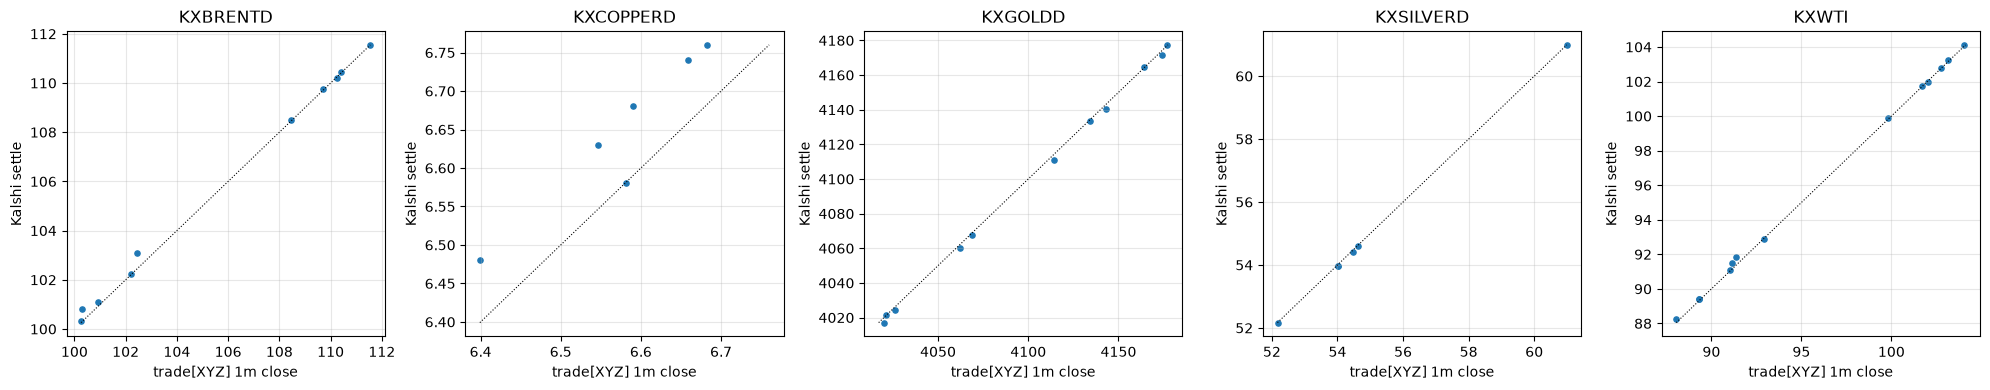

In [6]:
EOD = {"KXGOLDD": "GOLD", "KXSILVERD": "SILVER", "KXWTI": "CL", "KXCOPPERD": "COPPER", "KXBRENTD": "BRENTOIL"}
rows = []
for ser, sym in EOD.items():
    d = q(f"""with o as (select event_ticker, max(close_ms) close_ms, try_cast(any_value(expiration_value) as double) v
                         from kx.settlements where series='{ser}' group by event_ticker)
              select o.*, h.close hl from o join hl.candles h
                on h.interval='1m' and h.dex='xyz' and h.sym='{sym}' and h.open_ms + {MIN} = o.close_ms
              where v is not null order by close_ms""")
    if not d.empty:
        rows.append(d.assign(series=ser, sym=sym))
eod = pd.concat(rows)
fig, axes = plt.subplots(1, len(rows), figsize=(4 * len(rows), 4))
for ax, (ser, g) in zip(np.atleast_1d(axes), eod.groupby("series")):
    ax.scatter(g.hl, g.v, s=14); lim = [min(g.hl.min(), g.v.min()), max(g.hl.max(), g.v.max())]
    ax.plot(lim, lim, "k:", lw=.8); ax.set_title(ser); ax.set_xlabel("trade[XYZ] 1m close"); ax.set_ylabel("Kalshi settle")
plt.tight_layout()
eod.assign(gap=eod.v - eod.hl).groupby("series").agg(days=("v", "size"), median_gap=("gap", "median"),
                                                     corr=("gap", lambda s: np.corrcoef(eod.loc[s.index, "v"], eod.loc[s.index, "hl"])[0, 1]))

## 6. Daily real-world series on one date axis (Kalshi `outcomes`)

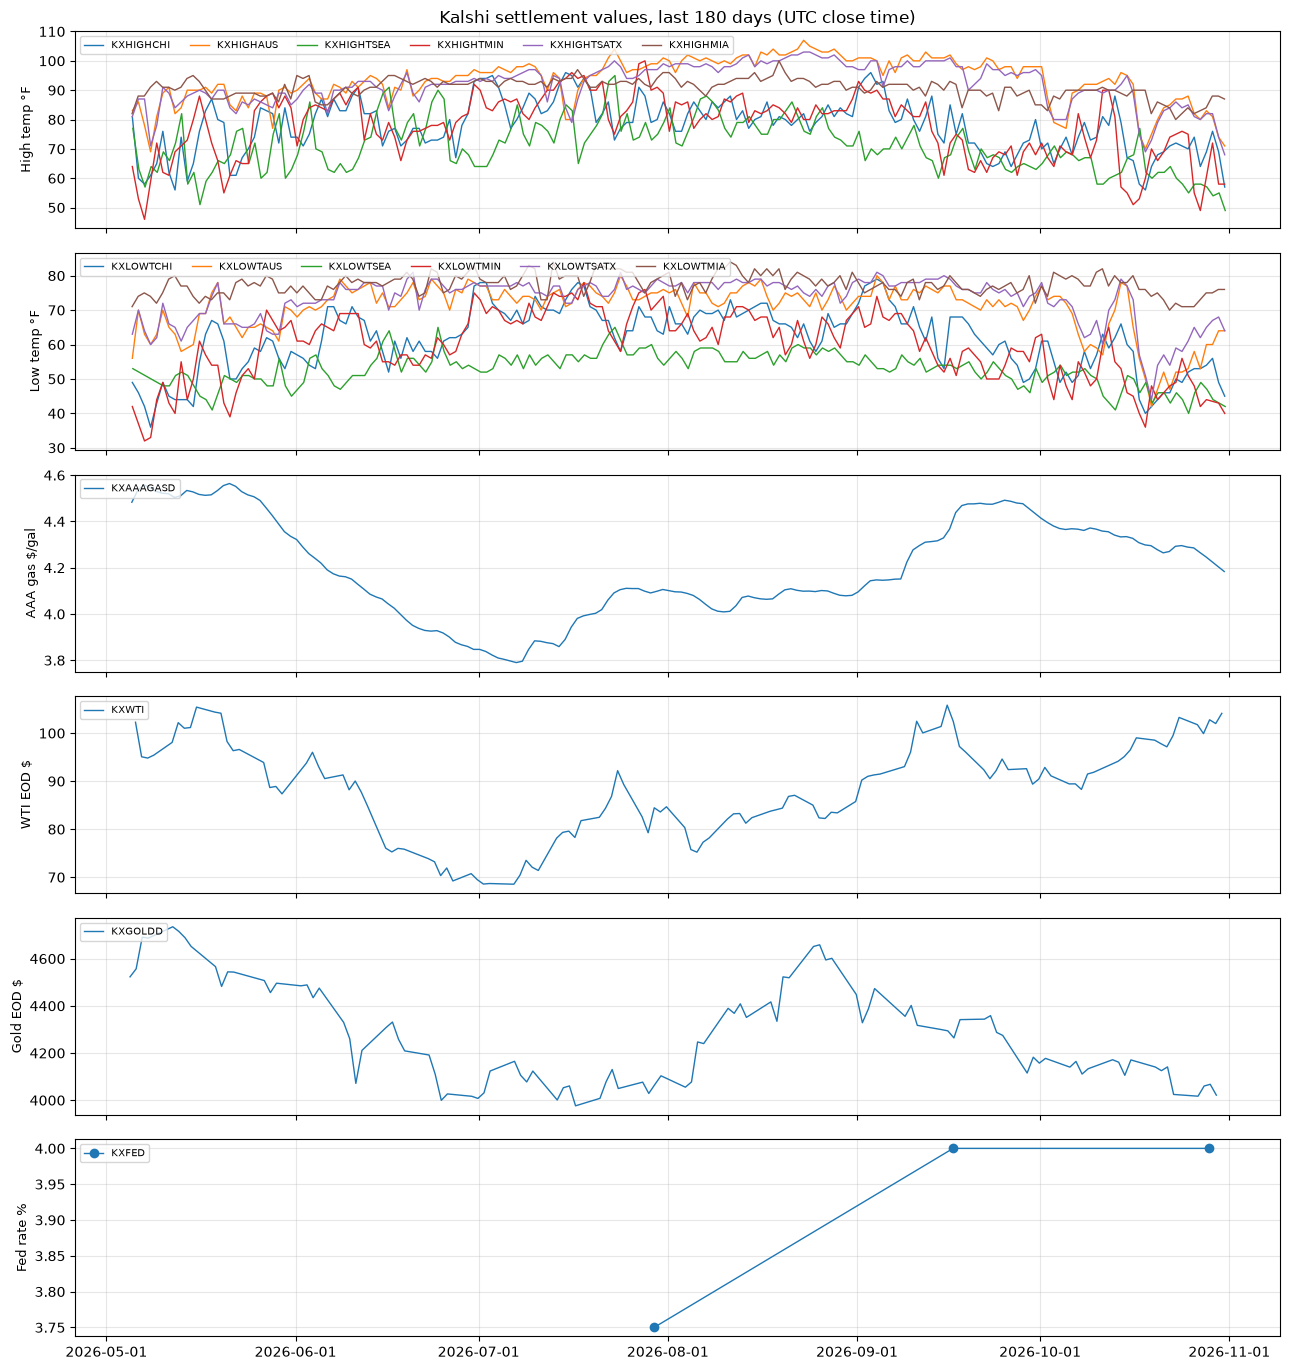

In [7]:
o = q("""select series, close_ts, value from kx.outcomes
         where value is not null and close_ts >= now() - interval 180 day""")
o["close_ts"] = pd.to_datetime(o.close_ts, utc=True)
panels = [("High temp °F", ["KXHIGHCHI", "KXHIGHAUS", "KXHIGHTSEA", "KXHIGHTMIN", "KXHIGHTSATX", "KXHIGHMIA"]),
          ("Low temp °F", ["KXLOWTCHI", "KXLOWTAUS", "KXLOWTSEA", "KXLOWTMIN", "KXLOWTSATX", "KXLOWTMIA"]),
          ("AAA gas $/gal", ["KXAAAGASD"]), ("WTI EOD $", ["KXWTI"]), ("Gold EOD $", ["KXGOLDD"]),
          ("Fed rate %", ["KXFED"])]
fig, axes = plt.subplots(len(panels), 1, figsize=(13, 2.3 * len(panels)), sharex=True)
for ax, (title, sers) in zip(axes, panels):
    for s in sers:
        g = o[o.series == s].sort_values("close_ts")
        ax.plot(g.close_ts, g.value, lw=1, label=s, marker="o" if s == "KXFED" else None)
    ax.set_ylabel(title, fontsize=9); ax.legend(fontsize=7, ncol=6, loc="upper left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d", tz="UTC"))
axes[0].set_title("Kalshi settlement values, last 180 days (UTC close time)")
plt.tight_layout()